#### Student name: Anupam Gupta
#### Student ID: 004016804

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [9]:
df = pd.read_csv("insurance_factors.csv")

In [10]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


### Data Understanding and Cleaning Summary

In [11]:

# Reusing the same code from part 1 to clean data
# Remove exact duplicate rows, keeping the first occurrence
df_clean = df.drop_duplicates(keep="first").reset_index(drop=True)


The dataset was checked for missing values, and no missing values were found. A duplicate record check identified one duplicated row at index 581. This duplicate was removed using the `drop_duplicates()` method in Pandas. No other rows required removal or modification. After cleaning, the final dataset contained **1,337 rows** and **7 columns**

### SECTION I: INDIVIDUAL, COMPARATIVE AND GROUPED VISUALIZATIONS

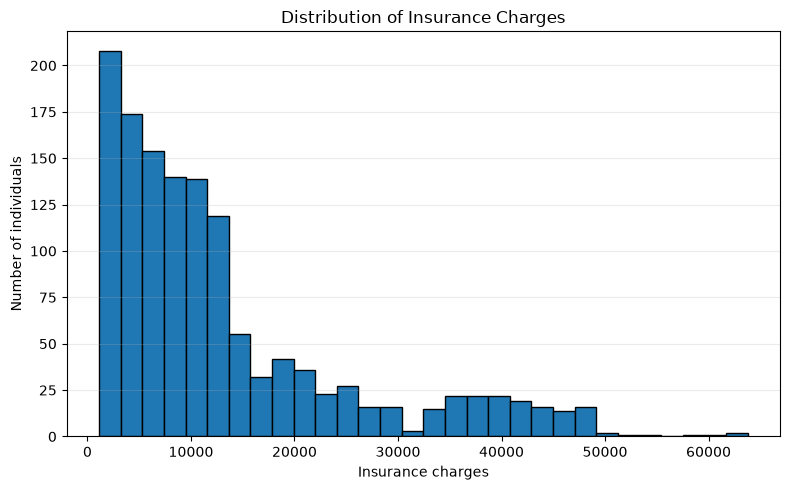

In [12]:
#Q1 
#Histogram

plt.figure(figsize=(8, 5))
plt.hist(df['charges'].dropna(), bins=30, edgecolor='black')
plt.title('Distribution of Insurance Charges')
plt.xlabel('Insurance charges')
plt.ylabel('Number of individuals')
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation**: The distribution is right skewed which means most indidviduals have relatively low insurance charges. Most insurance charges are concentrated below $15,000 dollars. From the histogram, we can clearly see that the frequency decreases as the insurance charges increase. The long tail on the right indicates that a relatively small number of individuals have exceptionally high insurance charges compared with the majority of the dataset.These unusually high charges extend the distribution toward larger values, showing that insurance costs vary considerably among individuals.

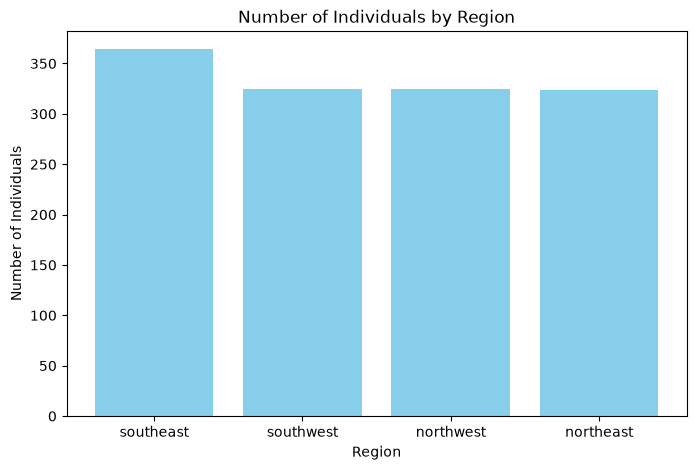

In [13]:
# Count the number of individuals in each region
region_counts = df['region'].value_counts()

# Create the bar chart
plt.figure(figsize=(8, 5))
plt.bar(region_counts.index, region_counts.values, color='skyblue')

plt.title('Number of Individuals by Region')
plt.xlabel('Region')
plt.ylabel('Number of Individuals')

plt.show()


**Interpretation** : The Southeast has the highest number of individuals, with 364, making it the most represented region in the dataset. The Southwest has 325 individuals, while the Northwest and Northeast each have 324 individuals. The difference between the most and least represented regions is only 40 individuals. Overall, the dataset has a fairly balanced distribution across all four regions, although the Southeast is slightly more represented. It turns out that no single geographical category overwhelmingly dominates the data set. 

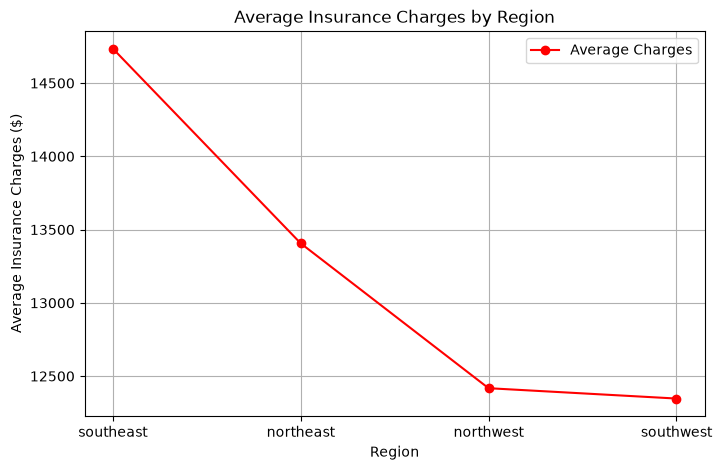

region
southeast    14735.411438
northeast    13406.384516
northwest    12417.575374
southwest    12346.937377
Name: charges, dtype: float64


In [14]:
#Q3: Lineplot
# Calculate average insurance charges by region
avg_charges_region = (df.groupby('region')['charges']
                      .mean()
                      .sort_values(ascending=False))

plt.figure(figsize=(8, 5))

plt.plot(avg_charges_region.index, avg_charges_region.values,
         color='red', marker='o', linestyle='-', label='Average Charges')

plt.title('Average Insurance Charges by Region')
plt.xlabel('Region')
plt.ylabel('Average Insurance Charges ($)')

plt.legend()
plt.grid(True)

plt.show()

print(avg_charges_region)


**Interpretation** : The Southeast has the highest average insurance charges at approximately 14,735 dollars, followed by the Northeast at 13,406 dollars. The Northwest and Southwest have lower average charges of approximately 12,451 dollars and 12,347 dollars, respectively. There is also a noticeable decrease in average insurance charges between the Southeast and Northeast, while the difference between the Northwest and Southwest is relatively small. 

### Section II:  RELATIONSHIP VISUALIZATIONS

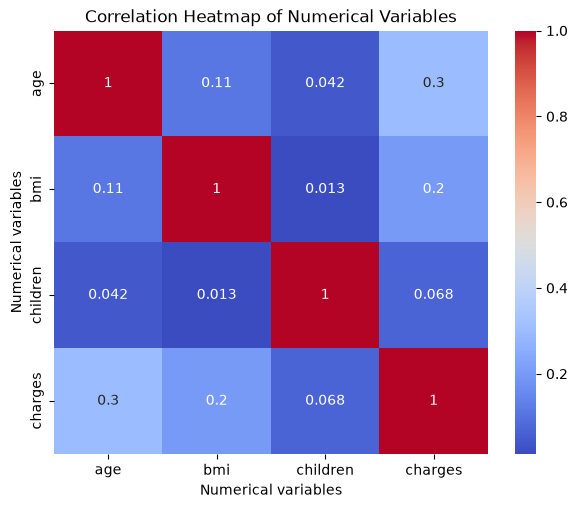

In [15]:
# Q4: Heatmap
numeric_cols = ['age', 'bmi', 'children', 'charges']
corr = df[numeric_cols].corr()

plt.figure(figsize=(7, 5.5))

sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap of Numerical Variables')
plt.xlabel('Numerical variables')
plt.ylabel('Numerical variables')

plt.show()


**Interpretation** : The heatmap shows a positive correlation between age and insurance charges (0.30), suggesting that insurance charges tend to increase as individuals get older. BMI and insurance charges (0.20) have a weak positive correlation which indicates a slight relationship between BMI and insurance costs. The number of children has a very weak correlation with insurance charges (0.067), suggesting little to no linear relationship between these variables

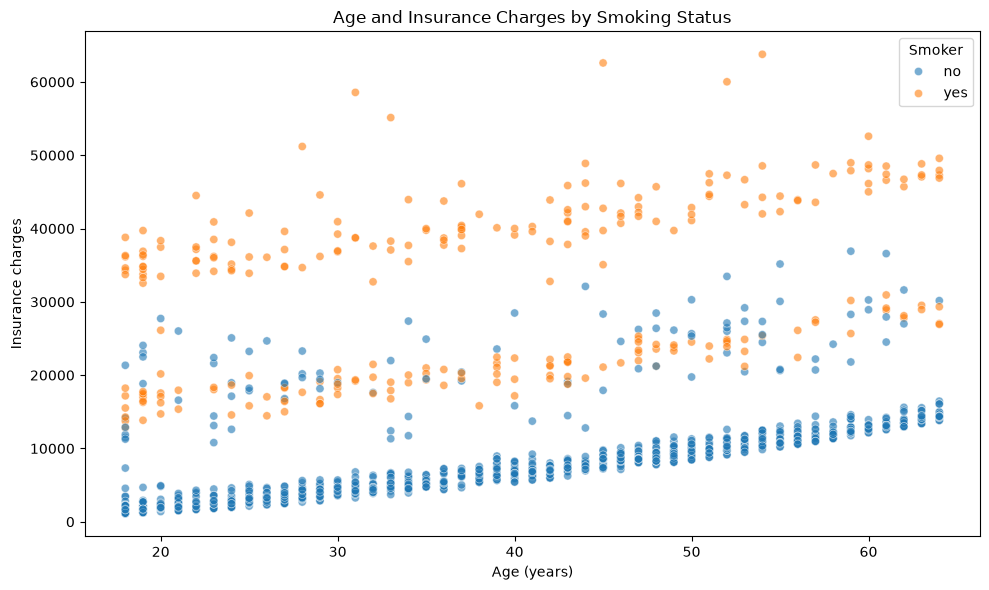

In [18]:
# Q4: Scatterplot

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='age', y='charges', hue='smoker',
                hue_order=['no', 'yes'], alpha=0.6, s=35)
plt.title('Age and Insurance Charges by Smoking Status')
plt.xlabel('Age (years)')
plt.ylabel('Insurance charges')
plt.legend(title='Smoker')
plt.tight_layout()
plt.show()



**Interpretation:** The charges tend to increase with age, but there is considerable variation among people of similar ages. When we color the points by smoking status, it shows that smokers often have higher charges than non-smokers of comparable ages.

### Summary and Conclusion

This project explored the insurance dataset containing 1,337 observations and 7 columns to identify patterns, distributions, and relationships among different variables. During data cleaning, no missing values were found, and one duplicated row was removed to ensure data consistency. The histogram revealed a right-skewed distribution of insurance charges, with most individuals having relatively lower charges. The regional count plot showed that the dataset is fairly balanced across all four regions, with the Southeast having the highest number of individuals. The group comparison revealed that the Southeast has the highest average insurance charges, while the Southwest has the lowest. The scatter plot showed a general positive relationship between age and insurance charges, with smokers generally having considerably higher charges than non-smokers. The correlation heatmap indicated that age has the strongest positive correlation with insurance charges (0.30), followed by BMI (0.20). The number of children showed a very weak correlation with insurance charges (0.067). Overall, the visualizations helped identify important patterns and differences in insurance charges across individuals and geographical regions. 